# Nashville City Cemetery, 1846–1979: cleaning and reading the cause-of-death ledger

**Juan Zavala** · AI for Analytics · built with Claude as a pair programmer

The city's interment ledger has 19,745 entries for burials in the Nashville City Cemetery from 1846 to 1979, written by hand by cemetery clerks. Once 75 duplicate entries are removed, that is 19,670 burials. This notebook answers the nine questions in the assignment. The assignment is also a test of where an AI assistant saves time and where it needs a human to check it, so each answer shows its own checks.

**Work in progress:** questions 1–5 are done so far.

**Labels used below**

| Label | Meaning |
|---|---|
| **Prompt** | What the assignment asks, as it was given to Claude |
| **[CLAUDE]** | Code or an answer written by Claude |
| **[CHECK]** | A verification. Every claim marked "asserted" has an `assert`, so a re-run fails loudly if a number moves |
| **[REVIEW]** | A judgment call, or a place where the AI needed human oversight |

Every number in the text was copied from this notebook's executed output (`results/facts.json`). The notebook needs only pandas, numpy and matplotlib, and was run under Python 3.9 (pandas 2.3.3) and Python 3.10.

In [1]:
import difflib, hashlib, json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle

import cause_of_death_rules as rules

DATA = Path('data/nashville_city_cemetery_interments_1846_1979.csv')
RESULTS, IMAGES = Path('results'), Path('images')
RESULTS.mkdir(exist_ok=True)
IMAGES.mkdir(exist_ok=True)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 70)

FACTS, TEXT = {}, {}          # every number quoted in the prose; saved to results/facts.json


def fact(key, value, text=None):
    """Record a number used in the prose (raw value + the exact text shown)."""
    FACTS[key] = value
    TEXT[key] = text if text is not None else (f'{value:,}' if isinstance(value, (int, np.integer)) else str(value))
    return value


def pct(x, d=1):
    return f'{100 * x:.{d}f}%'


def ranked(values):
    """value_counts with a fixed order for ties (count high to low, then name), so every environment ranks alike."""
    return values.value_counts().sort_index().sort_values(ascending=False, kind='stable')


# Chart style: the dataviz reference palette (light mode)
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE, AQUA, LIGHT_GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#c9c7bf'
AGE_ORDER = ['child', 'minors', 'young adults', 'middle aged', 'older adults', 'unknown']
AGE_COLORS = dict(zip(AGE_ORDER, ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281', '#c9c7bf']))
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'text.color': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False,
})


def save(fig, name):
    """Write the chart to images/ (the notebook also shows it inline below the cell)."""
    fig.savefig(IMAGES / name, dpi=150, bbox_inches='tight')


def age_group(age):
    """Question 6 bins on whole years: <=5 child, 6-17 minors, 18-30 young adults, 31-50 middle aged, >50 older adults, blank unknown."""
    a = np.floor(pd.to_numeric(age, errors='coerce'))
    out = np.select([a.isna(), a <= 5, a <= 17, a <= 30, a <= 50],
                    ['unknown', 'child', 'minors', 'young adults', 'middle aged'], 'older adults')
    return pd.Series(out, index=age.index)


def decade_label(year):
    """Question 5 format: 1846 -> "1840's"; blank year -> "unknown"."""
    y = pd.to_numeric(year, errors='coerce')
    lab = (y // 10 * 10).astype('Int64').astype(str) + "'s"
    return pd.Series(np.where(y.isna(), 'unknown', lab), index=year.index)

## Step 0. Load the ledger and check it before trusting it

The file is read as text (`dtype=str, keep_default_na=False`), so every code and blank comes through exactly as the clerks wrote it. Year and age are converted to numbers in helper columns, and the original columns stay untouched.

In [2]:
md5 = hashlib.md5(DATA.read_bytes()).hexdigest()
raw = pd.read_csv(DATA, dtype=str, keep_default_na=False)
assert md5 == '1fc59dc752d8c1ec10c0cff5aec09079', 'the data file is not the one this notebook was written for'

year_raw = pd.to_numeric(raw['Burial Year'], errors='coerce')
age_raw = pd.to_numeric(raw['Age'], errors='coerce')
fact('n_raw', len(raw))
fact('n_cols', raw.shape[1])
fact('n_spell_raw', int(raw['Cause of Death/Burial'].nunique()))
profile = pd.Series({
    'rows': len(raw),
    'columns': raw.shape[1],
    'burial years': f'{int(year_raw.min())}–{int(year_raw.max())}',
    'rows with no year': int(year_raw.isna().sum()),
    'rows with no age': f"{int(age_raw.isna().sum()):,} ({pct(age_raw.isna().mean())})",
    'ages of 100 or more': int((age_raw >= 100).sum()),
    'distinct cause spellings': raw['Cause of Death/Burial'].nunique(),
    'blank cause': int((raw['Cause of Death/Burial'].str.strip() == '').sum()),
    'Sex codes': raw['Sex'].value_counts().head(4).to_dict(),
    'Race codes': raw['Race'].value_counts().head(4).to_dict(),
}, name='value')
profile.to_frame()

,value
rows,19745
columns,14
burial years,1846–1979
rows with no year,2
rows with no age,"8,674 (43.9%)"
ages of 100 or more,39
distinct cause spellings,2210
blank cause,315
Sex codes,"{'M': 10108, 'F': 9372, '': 238, 'N': 7}"
Race codes,"{'W': 12887, 'B': 6735, 'D': 69, '': 47}"


### Duplicate ledger entries

The ledger comes in three sets of volumes. `4-1846`…`4-1860` and `5-1860`…`5-1881` are yearly books. The `6A`…`6Z` volumes are later lettered books, and they start in 1879. So for 1879–1881, some burials were written in both a yearly book and a lettered book. The cell below removes a lettered-book row when a yearly book already has the same named person in the same year and month.

Placeholder names such as "Infant" or "Unknown" are never removed, because two infants buried on the same day can be two different burials.

In [3]:
PLACEHOLDER = r'\b(?:inf\w*|inft|unknown|child|still|babe|baby|stranger|foundling|son of|daughter of|dau|boy|girl|man|woman)\b'
named = ~raw['Name'].str.lower().str.contains(PLACEHOLDER, regex=True) & raw['Name'].str.strip().ne('')
book = pd.Series(np.where(raw['Volume'].str.startswith('6'), 'lettered', 'yearly'), index=raw.index)

# (a) rows identical in every column except Volume: keep the yearly-book copy
cols_but_volume = [c for c in raw.columns if c != 'Volume']
srt = raw.assign(_lettered=(book == 'lettered').astype(int)).sort_values('_lettered', kind='stable')
same_entry = pd.Series(False, index=raw.index)
same_entry.loc[srt.index[srt.duplicated(subset=cols_but_volume, keep='first')]] = True
same_entry &= named

# (b) lettered-book copies of 1879-1881 burials already in a yearly book (same name, year and month;
#     day, age or spelling may differ by a typo)
key = raw['Name'].str.lower().str.replace(r'[^a-z]', '', regex=True) + '|' + raw['Burial Year'] + '|' + raw['Burial Month']
in_yearly = set(key[(book == 'yearly') & named])
repeat = named & (book == 'lettered') & key.isin(in_yearly) & year_raw.between(1879, 1881)

drop = same_entry | repeat
removed = raw[drop].assign(reason=np.where(same_entry[drop], 'identical except Volume', 'lettered-book copy of a 1879-1881 burial'))
removed.to_csv(RESULTS / 'duplicates_removed.csv', index_label='row')

df = raw[~drop].copy()
df['_year'] = pd.to_numeric(df['Burial Year'], errors='coerce')
df['_age'] = pd.to_numeric(df['Age'], errors='coerce')

fact('n_dup', int(drop.sum()))
fact('n_dup_identical', int(same_entry.sum()))
fact('n_clean', len(df))
assert removed['Volume'].str.startswith('6').all(), 'every removed copy should be from a lettered book'
assert year_raw[drop].between(1879, 1881).all()
print(f"removed {drop.sum()} duplicate rows ({same_entry.sum()} identical except Volume); {len(df):,} burials remain")
removed[['Volume', 'Name', 'Burial Month', 'Burial Day', 'Burial Year', 'Age', 'Cause of Death/Burial', 'reason']].head(6)

removed 75 duplicate rows (32 identical except Volume); 19,670 burials remain


,Volume,Name,Burial Month,Burial Day,Burial Year,Age,Cause of Death/Burial,reason
2170,6B,"Brown, M. G.",Apr,6,1881,18,Dropsey,lettered-book copy of a 1879-1881 burial
2172,6D,"Douglas, H.",Apr,8,1881,70,Heart Clab,lettered-book copy of a 1879-1881 burial
2175,6F,"Foster, Richard",Apr,12,1881,,Measles Compl,lettered-book copy of a 1879-1881 burial
2177,6H,"Hooper, A. J.",Apr,14,1881,81,Pneumonia,lettered-book copy of a 1879-1881 burial
2185,6K,"Kidwell, William",Apr,29,1881,26,Suicide,identical except Volume
2207,6C,"Crawford, A.",Feb,2,1881,66,Paralysis,identical except Volume


**[CHECK] Duplicates (asserted).** 75 rows are removed. All of them are lettered-book copies of 1879–1881 burials, and 32 of them are identical to the yearly-book row in every column except `Volume`. 19,670 burials remain, and every question below uses this de-duplicated table. The removed rows are saved in `results/duplicates_removed.csv`.

**[REVIEW] A famous entry is a reminder that the ledger is a clerk's record, not a fact sheet.** The row below is former President James K. Polk.

In [4]:
polk = raw[raw['Name'].str.contains('Ex president Polk', case=False)]
assert len(polk) == 1
fact('polk_age', int(polk['Age'].iloc[0]))
fact('polk_cause', polk['Cause of Death/Burial'].iloc[0])
polk[['Volume', 'Name', 'Burial Month', 'Burial Day', 'Burial Year', 'Age', 'Cause of Death/Burial', 'Remarks']]

,Volume,Name,Burial Month,Burial Day,Burial Year,Age,Cause of Death/Burial,Remarks
18256,4-1849,"Ex president Polk, J.K.",Jun,16,1849,64,Complicated,brick work


The ledger buries "Ex president Polk, J.K." on June 16, 1849, at age **64**, cause "**Complicated**". Polk was born in November 1795 and died in Nashville on June 15, 1849. That makes him 53, and most accounts attribute his death to cholera. (These dates come from Claude's general knowledge and were not checked against a source in this notebook, because this session had no web access. Juan should verify them before citing.)

The lesson for everything below: ages and causes are useful for patterns across thousands of burials, but any single entry can be wrong.

## Question 1. Fix spellings and group causes into `Cause of Death Updated`

> **Prompt (from the assignment, as given to Claude):** Examine the Cause of Death column. Fix spelling errors and group causes that belong together (for example, liver cancer and lung cancer → cancer; heart disease and heart attack → heart disease). Do not group different diseases that only share a symptom, such as Scarlet Fever and Yellow Fever. Ask me for details where you're unsure. When you're done, add the result as a new column named "Cause of Death Updated".

**How bad is the column?** In the 19,670 burials it has 2,209 distinct spellings. These are the twelve most common spellings in the cholera family, which turns out to be three different diseases:

In [5]:
cause_raw = df['Cause of Death/Burial']
cholera_like = cause_raw[cause_raw.str.lower().str.contains(r'chol|colney|colrey|colry|corey|colre', regex=True)
                         & ~cause_raw.str.lower().str.contains('cholic|cholick', regex=True)]
cholera_like.value_counts().head(12).rename_axis('as written').to_frame('burials').T

as written,Cholrea,Cholera,Cholera Infantum,Cholera Morbus,Cholrea Morbus,Cholera Inphantum,Cholrea Infantum,Colney Inphantom,Cholrea infantum,Cholra Morbus,Said Cholera,cholrea
burials,667,575,75,17,10,6,4,4,4,3,3,2


**[REVIEW] Questions Claude asked before grouping, and the default it used.** The assignment invites Claude to ask for details. Juan wasn't available while this was built, so each question below records the answer Claude chose, the reason, and the evidence. **Juan should confirm or change these.** Each one is a single line in `cause_of_death_rules.py`.

| Claude's question | Default used | Why |
|---|---|---|
| Is "Cholrea" the same as "Cholera"? | Yes, it's a spelling | It's how the 1849–50 and 1873 entries spell it, in the same epidemic years |
| Do "Cholera Morbus" and "Cholera Infantum" belong with Cholera? | **No**: three separate labels | Cholera morbus was acute gastroenteritis, and cholera infantum was infant summer diarrhea. Neither is epidemic cholera |
| "Summer complaint"? | With **Cholera Infantum** | The two names were used for the same infant summer diarrhea. Evidence below: almost every case is an infant |
| "S. Feever" and "T. Feever"? | **Scarlet Fever** and **Typhoid Fever** | Decided from the data (below): "S." cases are young children, as scarlet fever is; "T." cases are young adults, as typhoid is |
| Consumption, phthisis, tuberculosis? | One label, **Tuberculosis (consumption)** | Same disease under old and new names |
| "Phthisic"? | Its own label | Used for asthma as well as tuberculosis |
| "Lung fever", "inflammation of the lungs", "typhoid pneumonia"? | **Pneumonia** | Period names for pneumonia |
| "Flux"? | **Dysentery (flux)**, kept apart from Diarrhea | Flux was the period word for dysentery |
| "Yellow janders" / "yellow jaundice"? | **Jaundice**, not Yellow Fever | Same word "yellow", different disease |
| "Hives", "bold hives"? | Its own label | In old death records hives is not the skin rash, and its meaning is uncertain |
| "Congestive chill / fever"? | Its own label | Often severe malaria, but not certain enough to merge |
| "Membranous croup"? | **Croup** (flagged) | Often laryngeal diphtheria, but recorded as croup |
| "Child bed", "child bed fever"? | **Childbirth (incl. childbed fever)** | Both are deaths of mothers around childbirth |
| "Dropsy of the brain"? | **Hydrocephalus** | The standard period name |
| Birthplaces, undertakers, "died in Louisville"? | **Unknown** | These are notes, not causes |
| Two causes in one entry ("Measles & hooping cough")? | The cause written **first** | A few rows |
| "Tresmus nas" (trismus nascentium) and "mania a potu"? | **Tetanus** and **Alcoholism** | Newborn tetanus, and delirium tremens |
| "Complication" / "Complicated"? | Its own vague label | 755 rows whose meaning isn't recorded |

**[CLAUDE] The rules live in `cause_of_death_rules.py`.** A normalizer, a spelling dictionary and an ordered list of `(category, pattern)` rules are kept as data, so anyone can read and change them. A value that no rule matches keeps its corrected spelling instead of being forced into a group.

In [6]:
uniq = (cause_raw.value_counts().rename_axis('as written').reset_index(name='burials')
        .sort_values(['burials', 'as written'], ascending=[False, True], kind='stable').reset_index(drop=True))
decided = uniq['as written'].map(rules.categorize)
uniq['cleaned text'] = uniq['as written'].map(rules.clean_text)
uniq['Cause of Death Updated'] = decided.str[0]
uniq['method'] = decided.str[1]
uniq.to_csv(RESULTS / 'cause_mapping.csv', index=False)

mapping = dict(zip(uniq['as written'], uniq['Cause of Death Updated']))
pos = df.columns.get_loc('Cause of Death/Burial') + 1
df.insert(pos, 'Cause of Death Updated', cause_raw.map(mapping))

by_rule = uniq.groupby('method')['burials'].sum()
fact('n_spell', int(cause_raw.nunique()))
CHOLERA_FAMILY = ['Cholera', 'Cholera Morbus', 'Cholera Infantum (summer complaint)']
fact('n_cholera_family_spellings', int(uniq.loc[uniq['Cause of Death Updated'].isin(CHOLERA_FAMILY), 'as written'].nunique()))
fact('n_updated', int(df['Cause of Death Updated'].nunique()))
fact('n_rule_labels', int(uniq.loc[uniq['method'] == 'rule', 'Cause of Death Updated'].nunique()))
fact('n_complications', int((df['Cause of Death Updated'] == 'Complications (unspecified)').sum()))
fact('pct_rule', float(by_rule['rule'] / by_rule.sum()), pct(by_rule['rule'] / by_rule.sum()))
fact('n_spelling_only_rows', int(by_rule.get('spelling only', 0)))
fact('n_spelling_only_values', int((uniq['method'] == 'spelling only').sum()))
print(f"{df['Cause of Death Updated'].nunique()} labels from {cause_raw.nunique():,} spellings;",
      f"{by_rule['rule']:,} of {by_rule.sum():,} rows decided by a rule")
df.loc[:, ['Cause of Death/Burial', 'Cause of Death Updated']].sample(8, random_state=7)

232 labels from 2,209 spellings; 19,524 of 19,670 rows decided by a rule


,Cause of Death/Burial,Cause of Death Updated
18248,Cholrea,Cholera
13467,Still Born,Stillborn
11664,Flux,Dysentery (flux)
18174,Cholrea,Cholera
13585,Typhoid Fever,Typhoid Fever
17285,Cholrea,Cholera
7863,Unknown,Unknown
10785,Teething,Teething


In [7]:
# [CHECK] the assignment's own examples, plus the traps (asserted)
def cat(text):
    return rules.categorize(text)[0]

must = {
    'Cancer': ['Liver Cancer', 'Lung Cancer', 'Cancer of Stomach', 'Cancer on Breast', 'Cansor of Womb'],
    'Heart Disease': ['Heart Disease', 'Heart Attack', 'Heart Failure', 'Dis of Hart', 'Affection of the Heart'],
    'Scarlet Fever': ['Scarlet Fever', 'Scarlot Fever', 'Scarlett Feever', 'S. Feever'],
    'Yellow Fever': ['Yellow Fever'],
    'Jaundice': ['Yallow Janders', 'Yellow Jaundice', 'Jondice'],
    'Cholera': ['Cholrea', 'Cholera', 'Cholra'],
    'Cholera Morbus': ['Cholera Morbus', 'Cholrea Morbus', 'Colremobus'],
    'Cholera Infantum (summer complaint)': ['Cholera Infantum', 'Colney Inphantom', 'Summer Complt'],
    'Smallpox': ['Small Pox', 'Smal Pox'],
    'Chicken Pox': ['Chicken Pox'],
    'Tuberculosis (consumption)': ['Consumption', 'Consumson', 'Phthisis', 'Tuberculosis'],
    'Pneumonia': ['Pneumonia', 'Lung Fever', 'Infl. of Lungs', 'Typhoid Pneumonia', 'Numonia'],
    'Stillborn': ['Still Born', 'Stil Born', 'Stillborn', 'Still Bornd'],
}
for want, examples in must.items():
    for e in examples:
        assert cat(e) == want, (e, cat(e), want)
members = uniq.groupby('Cause of Death Updated')['cleaned text'].apply(lambda s: ' | '.join(s))
for label, text in members.items():
    assert not ('scarlet fever' in text and 'yellow fever' in text), label
    assert not ('chickenpox' in text and 'smallpox' in text), label
assert df['Cause of Death Updated'].notna().all() and (df['Cause of Death Updated'] != '').all()
assert df.columns[df.columns.get_loc('Cause of Death/Burial') + 1] == 'Cause of Death Updated'
print('all grouping checks pass')

all grouping checks pass


**[CHECK] Grouping (asserted).**
- The assignment's examples hold: liver cancer and lung cancer → Cancer, and heart disease and heart attack → Heart Disease.
- Scarlet Fever and Yellow Fever never share a label. Neither do Smallpox and Chicken Pox, or the three cholera terms.
- Every row has a value, and the new column sits immediately to the right of `Cause of Death/Burial`.

**[REVIEW] Two abbreviations were decided from the data, not guessed.**

In [8]:
norm = df['Cause of Death/Burial'].map(rules.normalize)
infant_name = df['Name'].str.lower().str.contains(r'\binf\w*|\binft|still|child|babe|baby', regex=True)
groups = {
    '"S. Feever"': norm.eq('s feever'),
    'scarlet fever, spelled out': df['Cause of Death Updated'].eq('Scarlet Fever') & ~norm.eq('s feever'),
    '"T. Feever"': norm.eq('t feever'),
    'typhoid fever, spelled out': df['Cause of Death Updated'].eq('Typhoid Fever') & ~norm.eq('t feever'),
    '"summer complaint" (all spellings)': df['Cause of Death/Burial'].map(rules.clean_text).eq('summer complaint'),
}
rows = []
for label, m in groups.items():
    s = df[m]
    rows.append({'cause as written': label, 'burials': len(s), 'years': f"{int(s['_year'].min())}–{int(s['_year'].max())}",
                 'median recorded age': s['_age'].median(), 'age <= 5 or infant name': pct(((s['_age'] <= 5) | infant_name[m]).mean(), 0)})
evidence = pd.DataFrame(rows).set_index('cause as written')
for key, row in [('s_fever_median_age', '"S. Feever"'), ('scarlet_median_age', 'scarlet fever, spelled out'),
                 ('t_fever_median_age', '"T. Feever"'), ('typhoid_median_age', 'typhoid fever, spelled out')]:
    v = float(evidence.loc[row, 'median recorded age'])
    fact(key, v, f'{v:g}')
fact('summer_infant_pct', evidence.loc['"summer complaint" (all spellings)', 'age <= 5 or infant name'])
assert evidence.loc['"S. Feever"', 'median recorded age'] <= 10 < evidence.loc['"T. Feever"', 'median recorded age']
evidence

,burials,years,median recorded age,age <= 5 or infant name
cause as written,,,,
"""S. Feever""",34,1846–1852,7.0,47%
"scarlet fever, spelled out",279,1847–1904,6.0,75%
"""T. Feever""",12,1846–1873,19.0,0%
"typhoid fever, spelled out",359,1852–1922,20.0,14%
"""summer complaint"" (all spellings)",202,1853–1896,1.0,99%


"S. Feever" has a median recorded age of 7, against 6 for scarlet fever spelled out. "T. Feever" has 19, against 20 for typhoid spelled out. Each abbreviation behaves like the disease it was mapped to. Summer complaint is an infant's illness: 99% of its burials are age 5 or under or have an infant name, which supports grouping it with cholera infantum.

**[REVIEW] Why fuzzy string matching was not allowed to choose the groups.** A common shortcut is to match each spelling to the closest category name by string similarity, as below. It fixes plain typos well. But it can't know medicine, so it confidently merges different diseases:

In [9]:
targets = ['cholera', 'cholera morbus', 'cholera infantum', 'scarlet fever', 'yellow fever', 'typhoid fever', 'bilious fever',
           'jaundice', 'smallpox', 'chicken pox', 'measles', 'consumption', 'teething', 'croup', 'diphtheria', 'brain fever',
           'dropsy', 'whooping cough', 'stillborn', 'old age', 'pneumonia', 'diarrhea', 'dysentery', 'heart disease', 'cancer']
tests = ['Cholrea', 'Measels', 'Stil Born', 'Teethin', 'Scarlot Fever',
         'Yallow Janders', 'Lung Fever', 'Child Bed Fever', 'Dropsey of Brain', 'Scrofula', 'Thrash']
rows = []
for t in tests:
    best = difflib.get_close_matches(t.lower(), targets, n=1, cutoff=0.0)[0]
    rows.append({'as written': t, 'closest by spelling': best,
                 'similarity': round(difflib.SequenceMatcher(None, t.lower(), best).ratio(), 2),
                 'rule-based answer': cat(t)})
fuzzy = pd.DataFrame(rows)
fuzzy['spelling match is right?'] = [r['rule-based answer'].lower().startswith(r['closest by spelling'][:6]) for _, r in fuzzy.iterrows()]
fact('fuzzy_wrong', int((~fuzzy['spelling match is right?']).sum()))
fuzzy

,as written,closest by spelling,similarity,rule-based answer,spelling match is right?
0,Cholrea,cholera,0.86,Cholera,True
1,Measels,measles,0.86,Measles,True
2,Stil Born,stillborn,0.89,Stillborn,True
3,Teethin,teething,0.93,Teething,True
4,Scarlot Fever,scarlet fever,0.92,Scarlet Fever,True
5,Yallow Janders,yellow fever,0.62,Jaundice,False
6,Lung Fever,bilious fever,0.70,Pneumonia,False
7,Child Bed Fever,typhoid fever,0.64,Childbirth (incl. childbed fever),False
8,Dropsey of Brain,dropsy,0.55,Hydrocephalus (dropsy of the brain),False
9,Scrofula,croup,0.62,Scrofula,False


Here is how the shortcut does. Plain typos are matched correctly: "Cholrea", "Measels" and "Stil Born". But 6 of these 11 entries end up under the wrong disease:
- "Yallow Janders" becomes *yellow fever*, though it is jaundice.
- "Lung Fever" becomes *bilious fever*, though it is pneumonia.
- "Child Bed Fever" becomes *typhoid fever*, though it is a childbirth death.
- "Dropsey of Brain" becomes plain *dropsy*, though it is hydrocephalus.
- "Scrofula" becomes *croup*, and "Thrash" (thrush) becomes *diphtheria*.

This is the oversight point of Question 1. String similarity proposed spelling fixes, and every grouping decision was written as an explicit rule and checked.

**Answer to Question 1.** The new column `Cause of Death Updated` turns 2,209 spellings into 232 labels. The three cholera labels alone absorb 81 spellings. 99.3% of rows are assigned by 100 explicit categories. The other 146 rows (135 rare or garbled entries such as "Piles" or "Locomotor Ataxia") keep their corrected text. The full raw → updated table is in `results/cause_mapping.csv`.

,distinct spellings
Cause of Death Updated,
Heart Disease,105
Bowel Inflammation / Disease,84
Lung Disease (other),72
Diarrhea,71
Tuberculosis (consumption),61
Pneumonia,59
"Kidney / Urinary Disease (Bright's disease, nephritis, gravel)",56
Cholera Infantum (summer complaint),52
Brain Fever / Inflammation,51


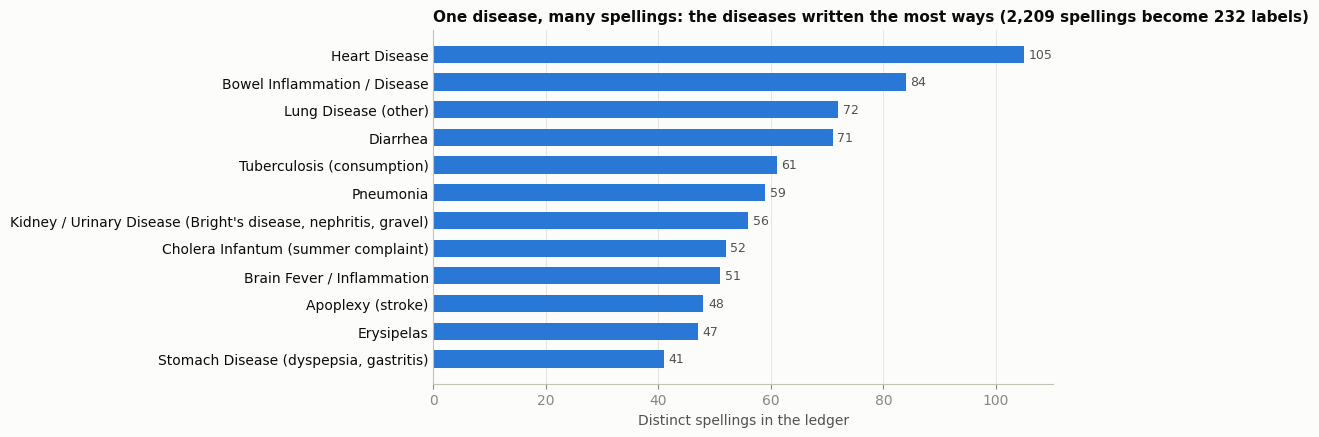

In [10]:
NOT_A_DISEASE = {rules.UNKNOWN, 'Accident', 'Gunshot', 'Homicide / Violence', 'Suicide', 'Drowning', 'Burns / Scalds', 'Poisoning / Overdose',
                 'Sudden Death', 'Suffocation (smothered, overlaid)', 'Exposure (heat or cold)', 'Wound (unspecified)', 'Killed in War'}
spellings = (uniq[(uniq['method'] == 'rule') & ~uniq['Cause of Death Updated'].isin(NOT_A_DISEASE)]
             .groupby('Cause of Death Updated')['as written'].nunique())
spellings = spellings.reset_index().sort_values(['as written', 'Cause of Death Updated'], ascending=[False, True]).set_index('Cause of Death Updated')['as written'].head(12)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(spellings.index[::-1], spellings.values[::-1], color=BLUE, height=0.62)
for y, v in enumerate(spellings.values[::-1]):
    ax.text(v + 0.8, y, f'{v}', va='center', color=INK2, fontsize=9)
ax.set_title(f"One disease, many spellings: the diseases written the most ways ({cause_raw.nunique():,} spellings become {df['Cause of Death Updated'].nunique()} labels)", fontsize=11)
ax.set_xlabel('Distinct spellings in the ledger')
ax.grid(axis='y', visible=False)
ax.tick_params(axis='y', length=0, labelcolor=INK)
save(fig, 'q1_spellings.png')
fact('most_spelled', spellings.index[0])
fact('most_spelled_n', int(spellings.iloc[0]))
spellings.to_frame('distinct spellings')

## Question 2. Top 10 known causes of death

> **Prompt:** Find the top 10 known causes of death from the updated column.

"Known" means any label except `Unknown`, which covers blanks, "Unknown", "Not known" and notes that aren't causes.

In [11]:
upd = df['Cause of Death Updated']
known = upd[upd != rules.UNKNOWN]
top10 = (known.value_counts().rename_axis('cause').reset_index(name='burials')
         .sort_values(['burials', 'cause'], ascending=[False, True], kind='stable').head(10).reset_index(drop=True))
top10.index = range(1, 11)
top10['share of known causes'] = (top10['burials'] / len(known)).map(lambda x: pct(x))
top10['share of all burials'] = (top10['burials'] / len(df)).map(lambda x: pct(x))
VAGUE = {'Complications (unspecified)', 'Fever (unspecified)', 'Cold', 'Unknown'}
top10['vague label?'] = top10['cause'].isin(VAGUE).map({True: 'yes', False: ''})
top10.to_csv(RESULTS / 'top10_causes.csv', index_label='rank')

fact('n_unknown_cause', int((upd == rules.UNKNOWN).sum()))
fact('n_known_cause', len(known))
fact('top1', top10.loc[1, 'cause'])
fact('top1_n', int(top10.loc[1, 'burials']))
fact('top1_pct', top10.loc[1, 'share of known causes'])
fact('top2', top10.loc[2, 'cause'])
fact('top2_n', int(top10.loc[2, 'burials']))
fact('top3', top10.loc[3, 'cause'])
fact('top3_n', int(top10.loc[3, 'burials']))
fact('top10_list', '; '.join(f"{i}. {c} ({n:,})" for i, (c, n) in enumerate(zip(top10['cause'], top10['burials']), 1)))
fact('top10_share', pct(top10['burials'].sum() / len(known)))
specific = ranked(known[~known.isin(VAGUE)]).head(10)
fact('top10_specific', '; '.join(specific.index))
top10

,cause,burials,share of known causes,share of all burials,vague label?
1,Tuberculosis (consumption),1843,10.6%,9.4%,
2,Stillborn,1303,7.5%,6.6%,
3,Cholera,1253,7.2%,6.4%,
4,Pneumonia,798,4.6%,4.1%,
5,Complications (unspecified),755,4.3%,3.8%,yes
6,Brain Fever / Inflammation,661,3.8%,3.4%,
7,Old Age,623,3.6%,3.2%,
8,Teething,599,3.4%,3.0%,
9,Dysentery (flux),565,3.2%,2.9%,
10,Measles,498,2.9%,2.5%,


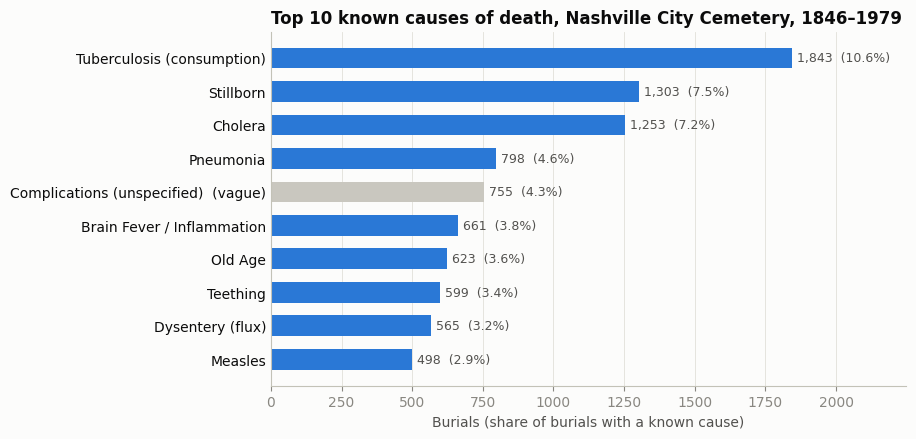

In [12]:
fig, ax = plt.subplots(figsize=(8.2, 4.6))
labels = [c + ('  (vague)' if c in VAGUE else '') for c in top10['cause']]
colors = [LIGHT_GRAY if c in VAGUE else BLUE for c in top10['cause']]
ax.barh(labels[::-1], top10['burials'].values[::-1], color=colors[::-1], height=0.62)
for y, (n, s) in enumerate(zip(top10['burials'].values[::-1], top10['share of known causes'].values[::-1])):
    ax.text(n + 18, y, f'{n:,}  ({s})', va='center', fontsize=9, color=INK2)
ax.set_title('Top 10 known causes of death, Nashville City Cemetery, 1846–1979')
ax.set_xlabel('Burials (share of burials with a known cause)')
ax.set_xlim(0, top10['burials'].max() * 1.22)
ax.grid(axis='y', visible=False)
ax.tick_params(axis='y', length=0, labelcolor=INK)
save(fig, 'q2_top10_causes.png')

**Answer to Question 2.** Of 19,670 burials, 17,402 have a known cause. The top 10 known causes are: 1. Tuberculosis (consumption) (1,843); 2. Stillborn (1,303); 3. Cholera (1,253); 4. Pneumonia (798); 5. Complications (unspecified) (755); 6. Brain Fever / Inflammation (661); 7. Old Age (623); 8. Teething (599); 9. Dysentery (flux) (565); 10. Measles (498). Together they cover 51.1% of burials with a known cause.

**[REVIEW] Why other students' lists may differ.**
- **Grouping choices:** for example, whether "summer complaint" joins cholera infantum, or whether "flux" is counted with diarrhea.
- **Whether *Stillborn* and *Old Age* count as causes.** They're recorded in the cause column, so they're kept here.
- **Vague labels:** "Complications (unspecified)" and "Fever (unspecified)" make the list even though they name no disease. Set them aside and the ten most frequent *specific* causes are: Tuberculosis (consumption); Stillborn; Cholera; Pneumonia; Brain Fever / Inflammation; Old Age; Teething; Dysentery (flux); Measles; Dropsy.
- **De-duplication:** it removes 75 repeated rows.

## Question 3. Years with a spike in burials, and does Claude's explanation hold up?

> **Prompt:** Find whether there were any years that had a spike in the number of burials. Explain the results. Does the explanation make sense? Do the numbers used as supporting evidence make sense?

**What counts as a spike?** The cemetery's yearly volume falls by 94% between the 1860's and the 1890's, as other cemeteries open, so a single fixed threshold would flag nearly every early year. The rule below compares each year with the **median of the five years before it**. It flags a year that reaches **1.5×** that baseline *and* has at least **50 more burials** than it. The second condition stops tiny counts after 1900 from qualifying; for example, a year going from 16 to 28 burials. The rule needs at least three earlier years.

In [13]:
yearly = df.groupby('_year').size()
yearly.index = yearly.index.astype(int)
yearly = yearly.reindex(range(int(yearly.index.min()), int(yearly.index.max()) + 1), fill_value=0)
baseline = pd.Series([yearly.loc[max(yearly.index.min(), y - 5):y - 1].median() if y - yearly.index.min() >= 3 else np.nan
                      for y in yearly.index], index=yearly.index)
spikes = pd.DataFrame({'burials': yearly, 'baseline (median of 5 prior years)': baseline})
spikes['ratio'] = (spikes['burials'] / spikes['baseline (median of 5 prior years)']).round(2)
spikes['extra burials'] = (spikes['burials'] - spikes['baseline (median of 5 prior years)']).round(0)
flagged = spikes[(spikes['ratio'] >= 1.5) & (spikes['extra burials'] >= 50)].copy()
flagged['top known cause'], flagged['cholera burials'], flagged['Black burials'] = '', 0, 0

upd_year = df.dropna(subset=['_year'])
cholera_by_year = upd_year[upd_year['Cause of Death Updated'] == 'Cholera'].groupby('_year').size()
race = df['Race'].str.upper().str.strip(' .')
for y in flagged.index:
    s = upd_year[upd_year['_year'] == y]['Cause of Death Updated']
    top = ranked(s[s != rules.UNKNOWN])
    flagged.loc[y, 'top known cause'] = f"{top.index[0]} ({top.iloc[0]:,}, {pct(top.iloc[0] / len(s), 0)})"
    flagged.loc[y, 'cholera burials'] = int(cholera_by_year.get(y, 0))
    flagged.loc[y, 'Black burials'] = int(((df['_year'] == y) & (race == 'B')).sum())
flagged.to_csv(RESULTS / 'spike_years.csv', index_label='year')
spike_years = [int(y) for y in flagged.index]
assert spike_years == [1849, 1850, 1863, 1864, 1865, 1866, 1873], spike_years
fact('spike_years', '1849, 1850, 1863, 1864, 1865, 1866 and 1873')
fact('n_spike_years', len(spike_years))
flagged

,burials,baseline (median of 5 prior years),ratio,extra burials,top known cause,cholera burials,Black burials
_year,,,,,,,
1849,745,447.0,1.67,298.0,"Cholera (305, 41%)",305,224
1850,809,461.5,1.75,348.0,"Cholera (300, 37%)",300,237
1863,836,482.0,1.73,354.0,"Tuberculosis (consumption) (86, 10%)",0,356
1864,1372,575.0,2.39,797.0,"Measles (112, 8%)",0,725
1865,1366,627.0,2.18,739.0,"Tuberculosis (consumption) (100, 7%)",0,770
1866,1354,836.0,1.62,518.0,"Cholera (388, 29%)",388,804
1873,559,285.0,1.96,274.0,"Cholera (137, 25%)",137,184


In [14]:
def chol(y):
    return int(cholera_by_year.get(y, 0))

def share(y, n):
    return n / int(yearly.loc[y])

for y in [1849, 1850, 1854, 1866, 1873]:
    fact(f'chol_{y}', chol(y))
    fact(f'chol_{y}_pct', share(y, chol(y)), pct(share(y, chol(y)), 0))
    fact(f'n_{y}', int(yearly.loc[y]))
for y in [1860, 1861, 1863, 1864, 1865, 1866]:
    fact(f'b{y}', int(((df['_year'] == y) & (race == 'B')).sum()))
    fact(f'w{y}', int(((df['_year'] == y) & (race == 'W')).sum()))
for y in [1863, 1864, 1865]:
    fact(f'n_{y}', int(yearly.loc[y]))
war = ranked(upd_year[upd_year['_year'].between(1863, 1865)]['Cause of Death Updated'])
fact('war_measles_1864', int(((upd_year['_year'] == 1864) & (upd_year['Cause of Death Updated'] == 'Measles')).sum()))
war_named = war[~war.index.isin(VAGUE | {'Stillborn', 'Premature Birth', 'Teething'})]
fact('war_top', ', '.join(f"{c.split(' (')[0].lower()} {n:,}" for c, n in war_named.head(5).items()))
free = df['Remarks'].str.lower().str.contains(r'f\. ?m\. ?c|f\. ?w\. ?c|free of color|\bfree\b', regex=True)
fact('free_1865', int((free & (df['_year'] == 1865)).sum()))
fact('free_1866', int((free & (df['_year'] == 1866)).sum()))
fact('n_1869', int(yearly.loc[1869]))
fact('n_1868', int(yearly.loc[1868]))
fact('n_1870', int(yearly.loc[1870]))
fact('n_d_1869', int((race == 'D').sum()))
assert set(df.loc[df['_year'] == 1869, 'Volume']) == {'5-1869'} and set(df.loc[race == 'D', '_year']) == {1869}
per_year = lambda a, b: yearly.loc[a:b].mean()
fact('decline_60s_90s', pct(1 - per_year(1890, 1899) / per_year(1860, 1869), 0))
fact('peak_year_n', int(yearly.max()))
fact('after_1900_max', int(yearly.loc[1901:].max()))
fact('n_1846_1870', int(yearly.loc[1846:1870].sum()))
fact('share_before_1871', pct(yearly.loc[1846:1870].sum() / yearly.sum()))

'76.5%'

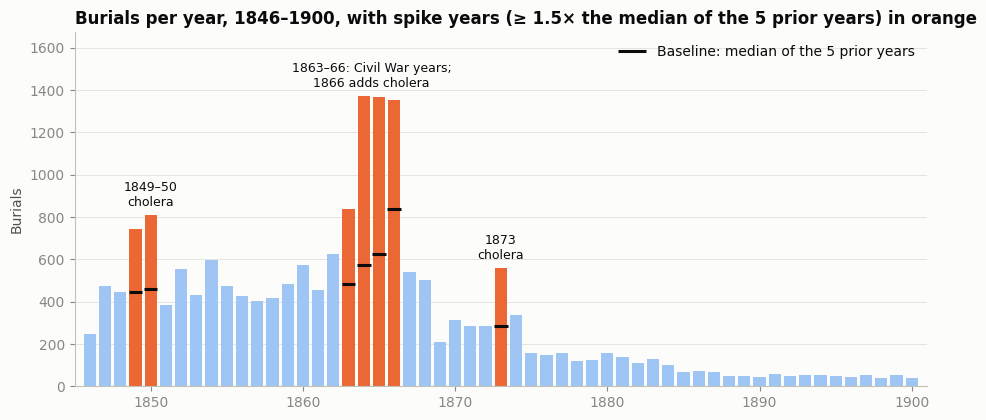

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.6))
yrs = yearly.loc[1846:1900]
cols = [ORANGE if y in spike_years else '#9ec5f4' for y in yrs.index]
ax.bar(yrs.index, yrs.values, color=cols, width=0.8)
for i, y in enumerate(spike_years):
    ax.hlines(baseline.loc[y], y - 0.45, y + 0.45, color=INK, lw=2.2, label='Baseline: median of the 5 prior years' if i == 0 else None)
notes = {1850: '1849–50\ncholera', 1864.5: '1863–66: Civil War years;\n1866 adds cholera', 1873: '1873\ncholera'}
for x, t in notes.items():
    top_y = yrs.loc[int(x) - 1:int(x) + 1].max()
    ax.text(x, top_y + 30, t, ha='center', va='bottom', fontsize=9, color=INK)
ax.set_ylim(0, yrs.max() * 1.22)
ax.set_xlim(1845, 1901)
ax.set_title('Burials per year, 1846–1900, with spike years (≥ 1.5× the median of the 5 prior years) in orange')
ax.set_ylabel('Burials')
ax.legend(loc='upper right')
ax.grid(axis='x', visible=False)
save(fig, 'q3_burials_by_year.png')

**[CLAUDE] Explanation of the spikes.** 7 years pass the 1.5× rule: 1849, 1850, 1863, 1864, 1865, 1866 and 1873.

1. **1849–1850: cholera.**
   - 1849 had 745 burials, and the updated cause column records cholera for 305 of them (41%).
   - 1850 had 809, with 300 cholera (37%).
   - A smaller cholera year, 1854, had 89 cholera burials out of 596. It doesn't pass the rule, because the five years before it include 1849–50.
2. **1863–1865: the Civil War years, without cholera.**
   - Burials ran 836, 1,372 and 1,366 for the three years, and no cholera is recorded in 1863–65.
   - Leaving aside stillbirths, teething and vague labels, the leading causes for those years are tuberculosis 294, pneumonia 184, measles 175, whooping cough 145, brain fever / inflammation 134. These are mostly respiratory and childhood infections, the kind that spread in crowded, poorly sheltered places; measles alone took 112 in 1864.
   - The increase falls mostly on **Black** Nashvillians. Black burials went from 140 in 1861 to 725 in 1864 and 770 in 1865. White burials went from 315 to 646 and 589.
   - Remarks such as "f. m. c." (free man of color) and "free" peak at 660 rows in 1865 and 770 in 1866.
3. **1866: cholera on top of the wartime level.** 388 of 1,354 burials (29%) are cholera. Black burials reached 804.
4. **1873: cholera again.** 137 of 559 burials (25%).

**Context from Claude's general knowledge.** This was not checked against sources in this notebook, because this session had no web access; Juan should verify it before citing.
- The United States had cholera epidemics in 1849–50, 1854, 1866 and 1873, and Nashville was hit in those waves.
- Union troops occupied Nashville in February 1862 and held it for the rest of the war, which made it a supply and hospital center.
- Thousands of people escaping slavery came to the occupied city, and many lived in crowded camps.
- Slavery ended in Tennessee in early 1865. That fits the "free" remarks appearing in 1865–66.

In [16]:
# [CHECK] recompute every number in the explanation another way (asserted)
text = df['Cause of Death/Burial'].str.lower()
asiatic = (text.str.contains(r'chol|colera|chalera', regex=True)
           & ~text.str.contains(r'morb|mobis|mobus|fobus|inf|inph|cholic|cholick|colic', regex=True))
for y in [1849, 1850, 1854, 1866, 1873]:
    by_raw_text = int((asiatic & (df['_year'] == y)).sum())
    assert by_raw_text == FACTS[f'chol_{y}'], (y, by_raw_text, FACTS[f'chol_{y}'])
for y in [1863, 1864, 1865]:
    assert FACTS.get(f'chol_{y}', chol(y)) == 0 and chol(y) == 0
assert int(yearly.sum()) == len(df) - int(df['_year'].isna().sum())
assert FACTS['b1866'] > 4 * FACTS['b1861'] and FACTS['w1866'] < 2 * FACTS['w1861']
print('every number in the explanation matches an independent count of the raw text')

every number in the explanation matches an independent count of the raw text


**[CHECK] Do the supporting numbers make sense? Yes (asserted).** Each cholera count was recomputed straight from the raw text, independently of the cleaning rules: any spelling containing "chol" or "colera", excluding the morbus, infantum and colic spellings. The two methods agree for every year quoted. The race counts also come straight from the `Race` column.

**[REVIEW] Does the explanation make sense?**
- **Cholera years: yes.** The ledger names the cause directly in 1849–50, 1866 and 1873.
- **War years: yes, with a correction to the obvious story.** The obvious story would be young soldiers. But the cause column shows camp and crowding diseases rather than wounds. The increase is concentrated in Black burials, and the age analysis in Question 4 finds no surge of young men.
- **What doesn't make sense, or needs a human:**
  - **The long decline after 1870 isn't falling mortality.** It shows burials moving to other cemeteries; after 1900 no year has more than 41 burials. 76.5% of all burials in the ledger happened before 1871.
  - **1869 looks like a gap in the records, not a healthy year.** It has 209 burials, between 504 in 1868 and 312 in 1870. All of 1869 comes from one volume, and that volume is the only place the unexplained race code `D` appears (69 rows).
  - **The ledger covers only this cemetery.** These are counts of burials here, not of deaths across Nashville.

## Question 4. Did the Civil War change the age of those buried?

> **Prompt:** There seems to be a spike during the Civil War. Ask Claude if the Civil War had any impact on the age of those being buried. Do the values and explanation make sense?

**What Claude expected before looking.** War years bring young men, so expect a higher share of young adults (18–30), a higher male share among them, and a lower median age. The test compares three five-year windows:
- **Before:** 1856–60
- **War:** 1861–65
- **After:** 1866–70

In [17]:
PERIODS = {'before (1856-60)': (1856, 1860), 'war (1861-65)': (1861, 1865), 'after (1866-70)': (1866, 1870)}
rng = np.random.default_rng(42)

def median_ci(a, n_boot=2000):
    a = np.asarray(a, dtype=float)
    meds = np.median(rng.choice(a, size=(n_boot, len(a)), replace=True), axis=1)
    return float(np.median(a)), float(np.percentile(meds, 2.5)), float(np.percentile(meds, 97.5))

grp_all = age_group(df['Age'])
rows = []
for who, mask in {'all': pd.Series(True, index=df.index), 'White': race == 'W', 'Black': race == 'B'}.items():
    for label, (lo, hi) in PERIODS.items():
        m = mask & df['_year'].between(lo, hi)
        s = df[m]
        g = grp_all[m]
        ages = s['_age'].dropna()
        med, lo_ci, hi_ci = median_ci(ages)
        ya = s[g == 'young adults']
        rows.append({'who': who, 'period': label, 'burials': len(s), 'age recorded': pct(ages.size / len(s), 0),
                     'median age': med, '95% CI': f'{lo_ci:g}–{hi_ci:g}',
                     'young adults (18-30)': pct((g == 'young adults').mean()),
                     'men among young adults': pct((ya['Sex'] == 'M').mean(), 0),
                     'child (<=5)': pct((g == 'child').mean()), 'minors (6-17)': pct((g == 'minors').mean()),
                     'older adults (51+)': pct((g == 'older adults').mean()), 'unknown age': pct((g == 'unknown').mean())})
civil = pd.DataFrame(rows)
civil.to_csv(RESULTS / 'civil_war_age.csv', index=False)

def cell(who, period, col):
    return civil[(civil['who'] == who) & (civil['period'].str.startswith(period))][col].iloc[0]

for who, k in [('all', 'all'), ('White', 'w'), ('Black', 'b')]:
    for p, kp in [('before', 'pre'), ('war', 'war'), ('after', 'post')]:
        fact(f'q4_{k}_{kp}', float(cell(who, p, 'median age')), f"{cell(who, p, 'median age'):g}")
        fact(f'q4_{k}_{kp}_ci', cell(who, p, '95% CI'))
        fact(f'q4_{k}_{kp}_ya', cell(who, p, 'young adults (18-30)'))
        fact(f'q4_{k}_{kp}_men', cell(who, p, 'men among young adults'))
        fact(f'q4_{k}_{kp}_n', int(cell(who, p, 'burials')))
        fact(f'q4_{k}_{kp}_unk', cell(who, p, 'unknown age'))
        fact(f'q4_{k}_{kp}_minors', cell(who, p, 'minors (6-17)'))
        fact(f'q4_{k}_{kp}_old', cell(who, p, 'older adults (51+)'))
ya_1866 = (df['_year'] == 1866) & (grp_all == 'young adults')
fact('q4_ya_cholera_1866', pct((df.loc[ya_1866, 'Cause of Death Updated'] == 'Cholera').mean(), 0))
civil

,who,period,burials,age recorded,median age,95% CI,young adults (18-30),men among young adults,child (<=5),minors (6-17),older adults (51+),unknown age
0,all,before (1856-60),2302,51%,33.0,31–35,14.2%,46%,1.7%,8.0%,12.7%,49.0%
1,all,war (1861-65),4656,49%,30.0,28–30,13.4%,44%,1.9%,10.7%,11.4%,50.8%
2,all,after (1866-70),2921,59%,30.0,28–30,18.9%,49%,2.4%,10.0%,11.0%,41.5%
3,White,before (1856-60),1560,49%,32.0,30–34,14.6%,50%,1.9%,7.2%,10.8%,50.8%
4,White,war (1861-65),2458,50%,32.0,30–34,14.0%,45%,1.9%,8.5%,12.5%,49.9%
5,White,after (1866-70),1335,58%,31.0,30–33,17.8%,53%,2.7%,7.7%,11.5%,42.4%
6,Black,before (1856-60),741,55%,35.0,31–40,13.5%,39%,1.5%,9.6%,16.7%,45.2%
7,Black,war (1861-65),2188,48%,27.0,25–28,12.7%,42%,1.8%,13.2%,10.2%,51.6%
8,Black,after (1866-70),1513,59%,28.0,26–30,19.4%,47%,1.5%,12.2%,10.8%,41.2%


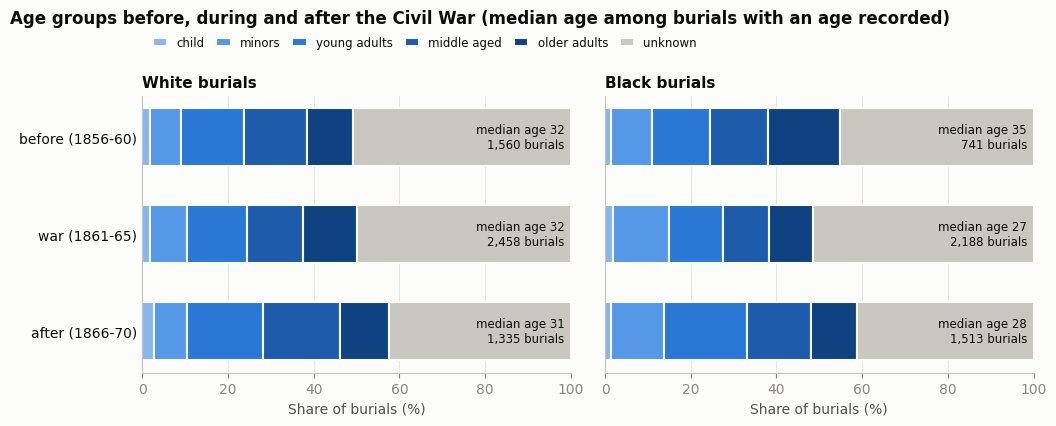

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), sharex=True)
for ax, who in zip(axes, ['White', 'Black']):
    left = np.zeros(3)
    for g in AGE_ORDER:
        vals = []
        for label, (lo, hi) in PERIODS.items():
            m = (race == ('W' if who == 'White' else 'B')) & df['_year'].between(lo, hi)
            vals.append((grp_all[m] == g).mean() * 100)
        ax.barh(list(PERIODS)[::-1], vals[::-1], left=left[::-1], color=AGE_COLORS[g], height=0.6,
                edgecolor=SURFACE, linewidth=1.5, label=g)
        left = left + np.array(vals)
    for y, label in enumerate(list(PERIODS)[::-1]):
        n = cell(who, label.split(' ')[0], 'burials')
        med = cell(who, label.split(' ')[0], 'median age')
        ax.text(98.5, y, f'median age {med:g}\n{n:,} burials', va='center', ha='right', fontsize=8.5, color=INK)
    ax.set_title(f'{who} burials', fontsize=11)
    ax.set_xlim(0, 100)
    ax.set_xlabel('Share of burials (%)')
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0, labelcolor=INK)
axes[1].tick_params(axis='y', labelleft=False)
axes[0].legend(ncol=6, loc='lower left', bbox_to_anchor=(0, 1.13), fontsize=8.5, handlelength=1.2, columnspacing=1)
fig.suptitle('Age groups before, during and after the Civil War (median age among burials with an age recorded)', x=0.01, ha='left', y=1.12, fontsize=12, fontweight='bold')
fig.subplots_adjust(wspace=0.08)
save(fig, 'q4_civil_war_age.png')

**[CHECK] Does the data match the expectation? Mostly no.** The medians are computed from burials with an age recorded; the bootstrap 95% CIs come from 2,000 resamples (seed 42).
- **All burials, median recorded age:**
  - Before: 33 (95% CI 31–35)
  - War: 30 (CI 28–30)
  - After: 30 (CI 28–30)
- **Young adults (18–30)** did not rise during the war: 14.2% → 13.4%. Men were 46% of young adults before and 44% during. A soldier-driven spike would raise both.
- **The change is among Black burials:**
  - Median recorded age fell from 35 (CI 31–40) to 27 (CI 25–28), while Black burials nearly tripled (741 → 2,188).
  - The shift comes from minors (6–17), not young adults: minors rose from 9.6% to 13.2% of Black burials, and older adults fell from 16.7% to 10.2%. Young adults stayed flat at 13.5% → 12.7%.
  - White burials barely moved: median 32 → 32, and 1,560 → 2,458 burials.
- **After the war**, young adults rose to 18.9% of all burials. Most of that is the 1866 cholera: it caused 43% of young-adult burials that year.

**[REVIEW] Does the explanation make sense?**
- **What holds up:**
  - The war did change who was buried here. The overall median fell by three years (33 → 30, with non-overlapping CIs), because many more Black Nashvillians were buried, and more of them were children and teenagers.
  - The causes in Question 3 (consumption, pneumonia, measles, whooping cough) fit refugees in crowded camps better than battle deaths.
- **What a human must keep in mind:**
  - **Age is missing for half of these burials** (50.8% during the war), and most of the missing are infants. The medians describe the people whose age was written down. For the same reason, "child" looks rare.
  - **Soldiers may be under-recorded here.** Many soldiers were buried in separate grounds and later moved. A few remarks mention a "Soldier Yard", but this ledger can't count them.
  - **The CIs overlap for White burials** (no detectable change), **but not for Black burials**.

## Question 5. Add a `decade` column next to the year

> **Prompt:** Make a new column named 'decade' next to the Year column, in the format 1840's.

In [19]:
pos = df.columns.get_loc('Burial Year') + 1
df.insert(pos, 'decade', decade_label(df['Burial Year']))
assert list(df.columns[pos - 1:pos + 1]) == ['Burial Year', 'decade']
assert (df.loc[df['Burial Year'] == '1846', 'decade'] == "1840's").all()
assert (df.loc[df['Burial Year'] == '1979', 'decade'] == "1970's").all()
assert (df.loc[df['Burial Year'] == '', 'decade'] == 'unknown').all()
assert df['decade'].str.fullmatch(r"\d{3}0's|unknown").all()
fact('n_decade_unknown', int((df['decade'] == 'unknown').sum()))
dec = df['decade'].value_counts().sort_index()
fact('top_decade', dec.drop('unknown', errors='ignore').idxmax())
fact('top_decade_n', int(dec.drop('unknown', errors='ignore').max()))
fact('top_decade_pct', pct(dec.drop('unknown', errors='ignore').max() / len(df)))
df[['Burial Year', 'decade']].drop_duplicates().head(3)

,Burial Year,decade
0,1979,1970's
3,1978,1970's
5,1977,1970's


In [20]:
dec.to_frame('burials').T

decade,1840's,1850's,1860's,1870's,1880's,1890's,1900's,1910's,1920's,1930's,1940's,1950's,1960's,1970's,unknown
burials,1914,4974,7840,2482,941,489,330,244,176,143,79,27,15,14,2


**[CHECK] (asserted).**
- `decade` sits immediately to the right of `Burial Year`.
- 1846 → `1840's` and 1979 → `1970's`.
- Every value matches the `1840's` pattern. The 2 rows with no year get `unknown`, the same convention Question 6 uses for blank ages.

**Answer to Question 5.** The busiest decade is the 1860's, with 7,840 burials (39.9% of the whole ledger).

In [21]:
out = df.drop(columns=['_year', '_age'])
out.to_csv(RESULTS / 'cemetery_clean.csv', index=False)
new_cols = [c for c in ['Cause of Death Updated', 'decade', 'age group'] if c in out.columns]
for c in new_cols:
    left = out.columns[out.columns.get_loc(c) - 1]
    print(f"{c!r} sits right after {left!r}")
(RESULTS / 'facts.json').write_text(json.dumps({'facts': {k: (v if not isinstance(v, (np.integer, np.floating, np.bool_)) else v.item())
                                                         for k, v in FACTS.items()}, 'text': TEXT}, indent=1, ensure_ascii=False))
print(f'saved results/cemetery_clean.csv ({len(out):,} rows, {out.shape[1]} columns) and {len(FACTS)} facts')

'Cause of Death Updated' sits right after 'Cause of Death/Burial'
'decade' sits right after 'Burial Year'
saved results/cemetery_clean.csv (19,670 rows, 16 columns) and 158 facts
